In [2]:
import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.decomposition import TruncatedSVD

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


In [34]:

import pandas as pd
from sklearn.model_selection import train_test_split

ds = pd.read_csv("IMDB_Dataset.csv")

ds["sentiment"] = ds["sentiment"].map({
    "negative": 0,
    "positive": 1
})

trainval, test = train_test_split(
    ds, test_size=0.2, random_state=42, stratify=ds["sentiment"]
)

train, val = train_test_split(
    trainval, test_size=0.25, random_state=42,
    stratify=trainval["sentiment"]
)

x_train = train["review"].astype(str).tolist()
y_train = train["sentiment"].to_numpy()

x_val = val["review"].astype(str).tolist()
y_val = val["sentiment"].to_numpy()

x_test = test["review"].astype(str).tolist()
y_test = test["sentiment"].to_numpy()



In [35]:
def clean_review(text):
    text = text.lower()
    text = re.sub(r"<br\\s*/?>", " ", text)
    text = re.sub(r"[^a-z0-9' ]+", " ", text)
    text = re.sub(r"\\s+", " ", text).strip()
    return text

train_clean = [clean_review(x) for x in x_train]
val_clean = [clean_review(x) for x in x_val]
test_clean = [clean_review(x) for x in x_test]


In [ ]:
classical_results = []

vectorizer_configs = {
    "Binary": CountVectorizer(binary=True, stop_words=["in", "of", "at", "a", "the"], max_features=30000),
    "Count_1_to_3gram": CountVectorizer(binary=False, ngram_range=(1, 3),
                                        stop_words=["in", "of", "at", "a", "the"], max_features=30000),
    "TFIDF_1_to_3gram": TfidfVectorizer(ngram_range=(1, 3),
                                        stop_words=["in", "of", "at", "a", "the"], max_features=30000),
}

for feature_name, vectorizer in vectorizer_configs.items():
    print(f"\\n=== Features: {feature_name} ===")
    Xtr = vectorizer.fit_transform(train_clean)
    Xv = vectorizer.transform(val_clean)
    Xte = vectorizer.transform(test_clean)

    linear_models = {
        "Logistic Regression": LogisticRegression(C=0.05, max_iter=1000, solver="liblinear"),
        "Linear SVM": LinearSVC(C=0.05, max_iter=3000),
    }

    for model_name, model in linear_models.items():
        model.fit(Xtr, y_train)
        val_pred = model.predict(Xv)
        test_pred = model.predict(Xte)
        row = {
            "experiment": f"{model_name} + {feature_name}",
            "validation_accuracy": accuracy_score(y_val, val_pred),
            "test_accuracy": accuracy_score(y_test, test_pred),
        }
        classical_results.append(row)
        print(row)

    max_train_tree = min(6000, Xtr.shape[0])
    max_eval_tree = min(3000, Xv.shape[0])
    svd_components = min(100, Xtr.shape[1] - 1, Xtr.shape[0] - 1)
    if svd_components >= 2:
        svd = TruncatedSVD(n_components=svd_components, random_state=SEED)
        Xtr_small = svd.fit_transform(Xtr[:max_train_tree])
        Xv_small = svd.transform(Xv[:max_eval_tree])
        ytr_small = y_train[:max_train_tree]
        yv_small = y_val[:max_eval_tree]

        tree_models = {
            "Random Forest": RandomForestClassifier(n_estimators=120, random_state=SEED, n_jobs=-1,
                                                     min_samples_leaf=2),
            "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=100, max_leaf_nodes=15,
                                                                      random_state=SEED),
        }
        for model_name, model in tree_models.items():
            model.fit(Xtr_small, ytr_small)
            val_pred = model.predict(Xv_small)
            row = {
                "experiment": f"{model_name} + {feature_name} (SVD/tree subset)",
                "validation_accuracy": accuracy_score(yv_small, val_pred),
                "test_accuracy": np.nan,
            }
            classical_results.append(row)
            print(row)

classical_df = pd.DataFrame(classical_results)
classical_df.sort_values("validation_accuracy", ascending=False)

\n=== Features: Binary ===
{'experiment': 'Logistic Regression + Binary', 'validation_accuracy': 0.8882, 'test_accuracy': 0.8942}
{'experiment': 'Linear SVM + Binary', 'validation_accuracy': 0.8778, 'test_accuracy': 0.8858}
{'experiment': 'Random Forest + Binary (SVD/tree subset)', 'validation_accuracy': 0.779, 'test_accuracy': nan}
{'experiment': 'Hist Gradient Boosting + Binary (SVD/tree subset)', 'validation_accuracy': 0.7853333333333333, 'test_accuracy': nan}
\n=== Features: Count_1_to_3gram ===
{'experiment': 'Logistic Regression + Count_1_to_3gram', 'validation_accuracy': 0.9029, 'test_accuracy': 0.9081}
{'experiment': 'Linear SVM + Count_1_to_3gram', 'validation_accuracy': 0.8912, 'test_accuracy': 0.8894}
{'experiment': 'Random Forest + Count_1_to_3gram (SVD/tree subset)', 'validation_accuracy': 0.7403333333333333, 'test_accuracy': nan}
{'experiment': 'Hist Gradient Boosting + Count_1_to_3gram (SVD/tree subset)', 'validation_accuracy': 0.746, 'test_accuracy': nan}
\n=== Features

,experiment,validation_accuracy,test_accuracy
4,Logistic Regression + Count_1_to_3gram,0.902900,0.9081
9,Linear SVM + TFIDF_1_to_3gram,0.896400,0.8990
5,Linear SVM + Count_1_to_3gram,0.891200,0.8894
0,Logistic Regression + Binary,0.888200,0.8942
1,Linear SVM + Binary,0.877800,0.8858
8,Logistic Regression + TFIDF_1_to_3gram,0.849400,0.8578
11,Hist Gradient Boosting + TFIDF_1_to_3gram (SVD...,0.825333,NaN
10,Random Forest + TFIDF_1_to_3gram (SVD/tree sub...,0.806333,NaN
3,Hist Gradient Boosting + Binary (SVD/tree subset),0.785333,NaN
2,Random Forest + Binary (SVD/tree subset),0.779000,NaN


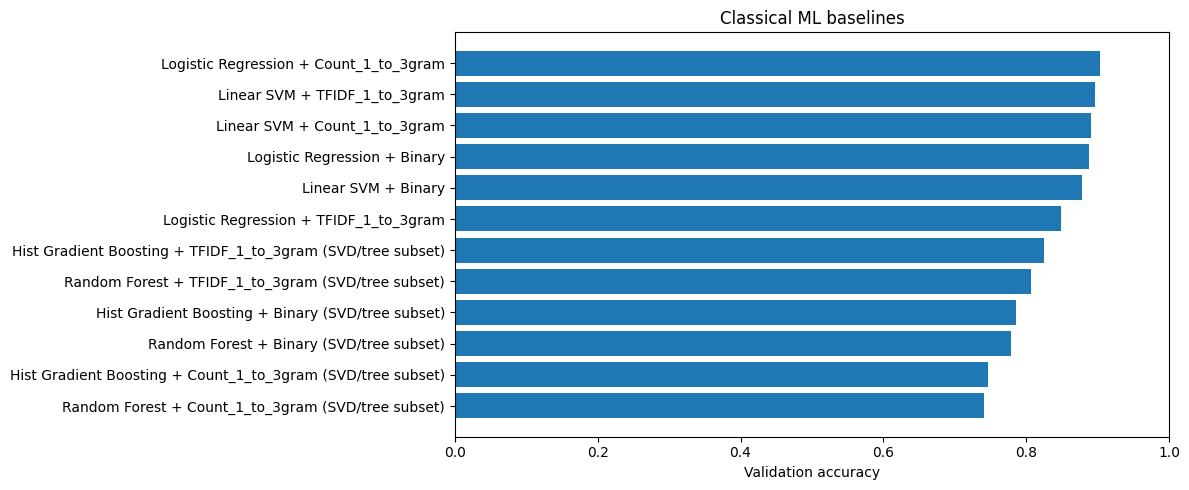

In [37]:
plot_df = classical_df.dropna(subset=["validation_accuracy"]).sort_values("validation_accuracy")
plt.figure(figsize=(12, max(5, 0.35 * len(plot_df))))
plt.barh(plot_df["experiment"], plot_df["validation_accuracy"])
plt.xlim(0, 1)
plt.xlabel("Validation accuracy")
plt.title("Classical ML baselines")
plt.tight_layout()
plt.show()

In [38]:
from sentence_transformers import SentenceTransformer

EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
sentence_encoder = SentenceTransformer(EMBEDDING_MODEL_NAME, device=str(DEVICE))

# Set these to smaller values while debugging if memory/time is limited.
EMBED_BATCH_SIZE = 64
X_train_emb = sentence_encoder.encode(x_train, batch_size=EMBED_BATCH_SIZE,
                                      show_progress_bar=True, convert_to_numpy=True,
                                      normalize_embeddings=False)
X_val_emb = sentence_encoder.encode(x_val, batch_size=EMBED_BATCH_SIZE,
                                    show_progress_bar=True, convert_to_numpy=True,
                                    normalize_embeddings=False)
X_test_emb = sentence_encoder.encode(x_test, batch_size=EMBED_BATCH_SIZE,
                                     show_progress_bar=True, convert_to_numpy=True,
                                     normalize_embeddings=False)

print(X_train_emb.shape, X_val_emb.shape, X_test_emb.shape)

Batches: 100%|██████████| 157/157 [00:20<00:00,  7.67it/s]

(30000, 384) (10000, 384) (10000, 384)


In [40]:
class ArrayDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).view(-1, 1)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class DenseEmbeddingClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)  # logits
        )
    def forward(self, x):
        return self.net(x)

def train_binary_model(model, train_loader, val_loader, epochs=10, lr=1e-3, patience=2):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()
    best_val_loss, best_state, stale = float("inf"), None, 0
    history = {"train_loss": [], "val_loss": [], "val_accuracy": []}

    for epoch in range(epochs):
        model.train()
        running_loss, seen = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(yb)
            seen += len(yb)
        train_loss = running_loss / seen

        model.eval()
        val_loss_sum, val_correct, val_seen = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb)
                val_loss_sum += criterion(logits, yb).item() * len(yb)
                pred = (torch.sigmoid(logits) >= 0.5).long()
                val_correct += (pred == yb.long()).sum().item()
                val_seen += len(yb)
        val_loss = val_loss_sum / val_seen
        val_acc = val_correct / val_seen
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)
        print(f"Epoch {epoch+1:02d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, val_acc={val_acc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss, best_state, stale = val_loss, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, 0
        else:
            stale += 1
            if stale >= patience:
                print("Early stopping.")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history

def evaluate_binary_model(model, X, y, batch_size=512):
    loader = DataLoader(ArrayDataset(X, y), batch_size=batch_size, shuffle=False)
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            logits = model(xb.to(DEVICE))
            preds.extend((torch.sigmoid(logits).cpu().numpy().ravel() >= 0.5).astype(int))
    return accuracy_score(y, preds), np.array(preds)

emb_train_loader = DataLoader(ArrayDataset(X_train_emb, y_train), batch_size=256, shuffle=True)
emb_val_loader = DataLoader(ArrayDataset(X_val_emb, y_val), batch_size=512, shuffle=False)

mlp_model = DenseEmbeddingClassifier(X_train_emb.shape[1])
mlp_model, mlp_history = train_binary_model(mlp_model, emb_train_loader, emb_val_loader, epochs=15)
mlp_val_acc, _ = evaluate_binary_model(mlp_model, X_val_emb, y_val)
mlp_test_acc, mlp_test_pred = evaluate_binary_model(mlp_model, X_test_emb, y_test)
print("Sentence-embedding MLP validation accuracy:", round(mlp_val_acc, 4))
print("Sentence-embedding MLP test accuracy:", round(mlp_test_acc, 4))

Epoch 01: train_loss=0.5634, val_loss=0.4375, val_acc=0.8014
Epoch 02: train_loss=0.4244, val_loss=0.4167, val_acc=0.8122
Epoch 03: train_loss=0.4117, val_loss=0.4135, val_acc=0.8144
Epoch 04: train_loss=0.4060, val_loss=0.4170, val_acc=0.8068
Epoch 05: train_loss=0.4026, val_loss=0.4068, val_acc=0.8181
Epoch 06: train_loss=0.3989, val_loss=0.4040, val_acc=0.8152
Epoch 07: train_loss=0.3958, val_loss=0.4040, val_acc=0.8170
Epoch 08: train_loss=0.3917, val_loss=0.4000, val_acc=0.8191
Epoch 09: train_loss=0.3878, val_loss=0.4004, val_acc=0.8181
Epoch 10: train_loss=0.3857, val_loss=0.3965, val_acc=0.8201
Epoch 11: train_loss=0.3796, val_loss=0.3957, val_acc=0.8207
Epoch 12: train_loss=0.3754, val_loss=0.4025, val_acc=0.8152
Epoch 13: train_loss=0.3729, val_loss=0.3948, val_acc=0.8230
Epoch 14: train_loss=0.3682, val_loss=0.3955, val_acc=0.8202
Epoch 15: train_loss=0.3647, val_loss=0.3956, val_acc=0.8215
Early stopping.
Sentence-embedding MLP validation accuracy: 0.823
Sentence-embedding 

In [41]:
from collections import Counter

MAX_VOCAB = 30000
MAX_LEN = 300
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"

counter = Counter()
for text in train_clean:
    counter.update(text.split())

most_common = counter.most_common(MAX_VOCAB - 2)
vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}
for word, _ in most_common:
    if word not in vocab:
        vocab[word] = len(vocab)

PAD_IDX, UNK_IDX = vocab[PAD_TOKEN], vocab[UNK_TOKEN]
print("Vocabulary size:", len(vocab))

def encode_review(text, max_len=MAX_LEN):
    ids = [vocab.get(token, UNK_IDX) for token in clean_review(text).split()[:max_len]]
    if len(ids) < max_len:
        ids += [PAD_IDX] * (max_len - len(ids))
    return ids

class ReviewDataset(Dataset):
    def __init__(self, texts, labels):
        self.X = torch.tensor(np.array([encode_review(t) for t in texts]), dtype=torch.long)
        self.y = torch.tensor(labels, dtype=torch.float32)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

lstm_train_ds = ReviewDataset(x_train, y_train)
lstm_val_ds = ReviewDataset(x_val, y_val)
lstm_test_ds = ReviewDataset(x_test, y_test)

LSTM_BATCH_SIZE = 128
lstm_train_loader = DataLoader(lstm_train_ds, batch_size=LSTM_BATCH_SIZE, shuffle=True)
lstm_val_loader = DataLoader(lstm_val_ds, batch_size=256, shuffle=False)
lstm_test_loader = DataLoader(lstm_test_ds, batch_size=256, shuffle=False)

Vocabulary size: 30000


In [42]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=100, hidden_dims=(64,), dropout=0.3,
                 pretrained_matrix=None, freeze_embeddings=False):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_IDX)
        if pretrained_matrix is not None:
            self.embedding.weight.data.copy_(torch.tensor(pretrained_matrix, dtype=torch.float32))
        self.embedding.weight.requires_grad = not freeze_embeddings

        layers = []
        input_dim = embedding_dim
        for i, hidden_dim in enumerate(hidden_dims):
            layers.append(nn.LSTM(input_dim, hidden_dim, batch_first=True,
                                  bidirectional=True))
            input_dim = hidden_dim * 2
        self.lstms = nn.ModuleList(layers)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(input_dim, 1)

    def forward(self, token_ids):
        x = self.embedding(token_ids)
        for lstm in self.lstms:
            x, _ = lstm(x)
            x = self.dropout(x)
        # Average sequence states, excluding padding tokens.
        mask = (token_ids != PAD_IDX).unsqueeze(-1)
        x = x * mask
        pooled = x.sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.classifier(self.dropout(pooled))

def train_lstm_model(model, epochs=5, lr=1e-3, patience=2):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    criterion = nn.BCEWithLogitsLoss()
    best_loss, best_state, stale = float("inf"), None, 0
    history = {"train_loss": [], "val_loss": [], "val_accuracy": []}

    for epoch in range(epochs):
        model.train()
        total_loss, total_n = 0.0, 0
        for xb, yb in tqdm(lstm_train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=False):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE).view(-1, 1)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * len(yb)
            total_n += len(yb)

        model.eval()
        val_loss_sum, correct, n = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in lstm_val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE).view(-1, 1)
                logits = model(xb)
                val_loss_sum += criterion(logits, yb).item() * len(yb)
                correct += ((torch.sigmoid(logits) >= 0.5) == yb.bool()).sum().item()
                n += len(yb)
        train_loss = total_loss / total_n
        val_loss = val_loss_sum / n
        val_acc = correct / n
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)
        print(f"Epoch {epoch+1}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, val_acc={val_acc:.4f}")

        if val_loss < best_loss:
            best_loss, stale = val_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= patience:
                print("Early stopping.")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history

def evaluate_lstm(model, loader):
    model.eval()
    preds, actual = [], []
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb.to(DEVICE))
            preds.extend((torch.sigmoid(logits).cpu().numpy().ravel() >= 0.5).astype(int))
            actual.extend(yb.numpy().astype(int))
    return accuracy_score(actual, preds), np.array(preds)

# Single BiLSTM
single_lstm = LSTMClassifier(len(vocab), embedding_dim=100, hidden_dims=(64,), dropout=0.3)
single_lstm, single_lstm_history = train_lstm_model(single_lstm, epochs=5)
single_lstm_val_acc, _ = evaluate_lstm(single_lstm, lstm_val_loader)
single_lstm_test_acc, single_lstm_pred = evaluate_lstm(single_lstm, lstm_test_loader)
print("Single BiLSTM val/test:", round(single_lstm_val_acc, 4), round(single_lstm_test_acc, 4))

# Double BiLSTM
double_lstm = LSTMClassifier(len(vocab), embedding_dim=100, hidden_dims=(64, 32), dropout=0.3)
double_lstm, double_lstm_history = train_lstm_model(double_lstm, epochs=5)
double_lstm_val_acc, _ = evaluate_lstm(double_lstm, lstm_val_loader)
double_lstm_test_acc, double_lstm_pred = evaluate_lstm(double_lstm, lstm_test_loader)
print("Double BiLSTM val/test:", round(double_lstm_val_acc, 4), round(double_lstm_test_acc, 4))

Epoch 1: train_loss=0.5297, val_loss=0.4248, val_acc=0.8056


Epoch 2: train_loss=0.3250, val_loss=0.3340, val_acc=0.8511


Epoch 3: train_loss=0.2506, val_loss=0.3151, val_acc=0.8678


Epoch 4: train_loss=0.1936, val_loss=0.3057, val_acc=0.8753


Epoch 5: train_loss=0.1433, val_loss=0.3671, val_acc=0.8742
Single BiLSTM val/test: 0.8753 0.8794


Epoch 1: train_loss=0.5182, val_loss=0.3720, val_acc=0.8364


Epoch 2: train_loss=0.3113, val_loss=0.3096, val_acc=0.8700


Epoch 3: train_loss=0.2374, val_loss=0.3000, val_acc=0.8794


Epoch 4: train_loss=0.1794, val_loss=0.2943, val_acc=0.8835


Epoch 5: train_loss=0.1322, val_loss=0.3278, val_acc=0.8802
Double BiLSTM val/test: 0.8835 0.8866


In [ ]:


GLOVE_PATH = "glove.6B.100d.txt"

def build_glove_matrix(glove_path, vocab, embedding_dim=100):
    matrix = np.random.normal(0, 0.05, (len(vocab), embedding_dim)).astype(np.float32)
    matrix[PAD_IDX] = 0
    found = 0
    with open(glove_path, encoding="utf8") as f:
        for line in tqdm(f, desc="Reading GloVe"):
            parts = line.rstrip().split(" ")
            word, values = parts[0], parts[1:]
            if word in vocab and len(values) == embedding_dim:
                matrix[vocab[word]] = np.asarray(values, dtype=np.float32)
                found += 1
    print(f"Matched {found:,} vocabulary words out of {len(vocab):,}")
    return matrix



In [47]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModelForSequenceClassification

BERT_MODEL_NAME = "distilbert/distilbert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL_NAME,
    num_labels=2
).to(DEVICE)

MAX_LEN_BERT = 256
BERT_BATCH_SIZE = 16


class BertReviewDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN_BERT):
        self.texts = list(texts)
        self.labels = np.asarray(labels, dtype=np.int64)
        self.tokenizer = tokenizer
        self.max_len = max_len
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        encoded = self.tokenizer(
            self.texts[idx], truncation=True, padding="max_length",
            max_length=self.max_len, return_tensors="pt"
        )
        item = {k: v.squeeze(0) for k, v in encoded.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

bert_train_loader = DataLoader(BertReviewDataset(x_train, y_train, bert_tokenizer),
                               batch_size=BERT_BATCH_SIZE, shuffle=True)
bert_val_loader = DataLoader(BertReviewDataset(x_val, y_val, bert_tokenizer),
                             batch_size=BERT_BATCH_SIZE * 2, shuffle=False)
bert_test_loader = DataLoader(BertReviewDataset(x_test, y_test, bert_tokenizer),
                              batch_size=BERT_BATCH_SIZE * 2, shuffle=False)

bert_model = AutoModelForSequenceClassification.from_pretrained(BERT_MODEL_NAME, num_labels=2).to(DEVICE)
bert_optimizer = AdamW(bert_model.parameters(), lr=2e-5)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 11172.89it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 8919.50it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: 

In [48]:
def run_bert_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, total_n, correct = 0.0, 0, 0
    all_preds, all_labels = [], []

    for batch in tqdm(loader, leave=False):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(**batch)
            loss = outputs.loss
            logits = outputs.logits
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

        labels = batch["labels"]
        preds = logits.argmax(dim=1)
        total_loss += loss.item() * len(labels)
        total_n += len(labels)
        correct += (preds == labels).sum().item()
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    return total_loss / total_n, correct / total_n, np.array(all_preds), np.array(all_labels)

BERT_EPOCHS = 2
best_val_loss, best_state = float("inf"), None
bert_history = {"train_loss": [], "val_loss": [], "val_accuracy": []}

for epoch in range(BERT_EPOCHS):
    train_loss, train_acc, _, _ = run_bert_epoch(bert_model, bert_train_loader, bert_optimizer)
    val_loss, val_acc, _, _ = run_bert_epoch(bert_model, bert_val_loader)
    bert_history["train_loss"].append(train_loss)
    bert_history["val_loss"].append(val_loss)
    bert_history["val_accuracy"].append(val_acc)
    print(f"Epoch {epoch+1}: train_loss={train_loss:.4f}, train_acc={train_acc:.4f}, "
          f"val_loss={val_loss:.4f}, val_acc={val_acc:.4f}")
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in bert_model.state_dict().items()}

if best_state is not None:
    bert_model.load_state_dict(best_state)

bert_val_loss, bert_val_acc, _, _ = run_bert_epoch(bert_model, bert_val_loader)
bert_test_loss, bert_test_acc, bert_test_pred, bert_test_y = run_bert_epoch(bert_model, bert_test_loader)
print("BERT validation accuracy:", round(bert_val_acc, 4))
print("BERT test accuracy:", round(bert_test_acc, 4))

Epoch 1: train_loss=0.2855, train_acc=0.8831, val_loss=0.2237, val_acc=0.9098


Epoch 2: train_loss=0.1828, train_acc=0.9378, val_loss=0.2760, val_acc=0.9099


BERT validation accuracy: 0.9098
BERT test accuracy: 0.909


In [49]:
summary_rows = [
    {"model": "Sentence-embedding MLP", "validation_accuracy": mlp_val_acc, "test_accuracy": mlp_test_acc},
    {"model": "Single BiLSTM", "validation_accuracy": single_lstm_val_acc, "test_accuracy": single_lstm_test_acc},
    {"model": "Double BiLSTM", "validation_accuracy": double_lstm_val_acc, "test_accuracy": double_lstm_test_acc},
    {"model": "BERT mini", "validation_accuracy": bert_val_acc, "test_accuracy": bert_test_acc},
]
summary_df = pd.concat([pd.DataFrame(summary_rows), classical_df], ignore_index=True)
summary_df.sort_values("validation_accuracy", ascending=False)

,model,validation_accuracy,test_accuracy,experiment
3,BERT mini,0.909800,0.9090,NaN
8,NaN,0.902900,0.9081,Logistic Regression + Count_1_to_3gram
13,NaN,0.896400,0.8990,Linear SVM + TFIDF_1_to_3gram
9,NaN,0.891200,0.8894,Linear SVM + Count_1_to_3gram
4,NaN,0.888200,0.8942,Logistic Regression + Binary
2,Double BiLSTM,0.883500,0.8866,NaN
5,NaN,0.877800,0.8858,Linear SVM + Binary
1,Single BiLSTM,0.875300,0.8794,NaN
12,NaN,0.849400,0.8578,Logistic Regression + TFIDF_1_to_3gram
15,NaN,0.825333,NaN,Hist Gradient Boosting + TFIDF_1_to_3gram (SVD...


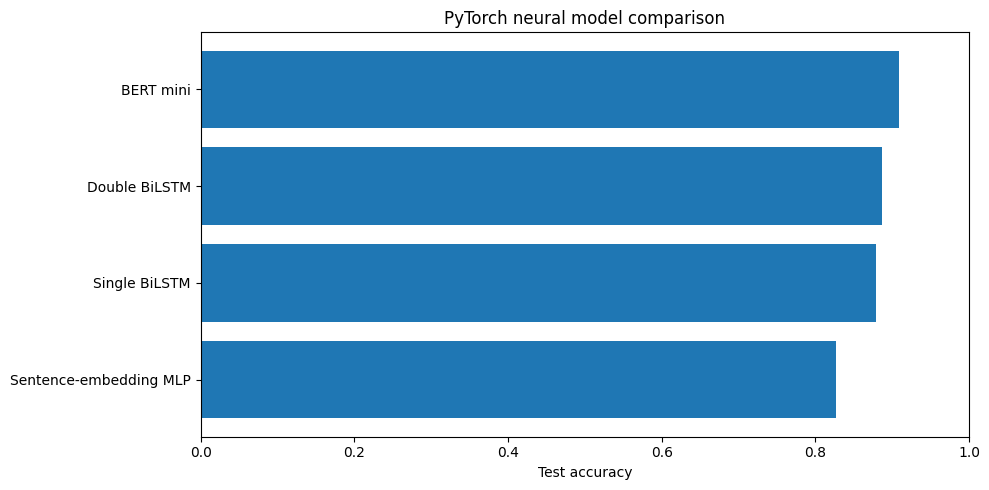

In [50]:
deep_df = pd.DataFrame(summary_rows).sort_values("test_accuracy")
plt.figure(figsize=(10, 5))
plt.barh(deep_df["model"], deep_df["test_accuracy"])
plt.xlim(0, 1)
plt.xlabel("Test accuracy")
plt.title("PyTorch neural model comparison")
plt.tight_layout()
plt.show()

In [51]:
def predict_sentiment_bert(text):
    bert_model.eval()
    encoded = bert_tokenizer(text, truncation=True, padding="max_length",
                             max_length=MAX_LEN_BERT, return_tensors="pt")
    encoded = {k: v.to(DEVICE) for k, v in encoded.items()}
    with torch.no_grad():
        logits = bert_model(**encoded).logits
        probs = torch.softmax(logits, dim=1)[0]
    label = int(probs.argmax().item())
    return {"sentiment": "positive" if label == 1 else "negative",
            "negative_probability": float(probs[0].item()),
            "positive_probability": float(probs[1].item())}

predict_sentiment_bert("The acting was excellent and the story was surprisingly moving.")

{'sentiment': 'positive',
 'negative_probability': 0.036288678646087646,
 'positive_probability': 0.9637113213539124}